# 01 — Data exploration

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MunenNoKage/DEQUBIT/blob/main/notebooks/01-data-exploration.ipynb)


In [1]:
import sys

if "google.colab" in sys.modules:
    !git clone https://github.com/MunenNoKage/DEQUBIT.git
    %cd DEQUBIT
    !pip install -q -r requirements.txt
    !pip install -q -e .

In [5]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

train_clean_path = "../data/1_clean_train.h5"
train_noisy_path = "../data/3_noisy_train.h5"

with h5py.File(train_clean_path, 'r') as f:    
    print("\n=== Attributes ===")
    for key, val in f.attrs.items():
        print(f"{key}: {val}")


=== Attributes ===
P_target_sum_check: 1.0
num_bitstrings: 32
num_bricks: 3
num_circuits: 2000
num_qubits: 5
num_shots: 10000
seed_circuits: 42
seed_shots: 123
split: train


In [27]:
def unpack_bitstrings(packed_array, num_bits=5):
    unpacked = np.unpackbits(packed_array, axis=1)
    return unpacked[:, :num_bits]

with h5py.File(train_clean_path, 'r') as f_c, \
     h5py.File(train_noisy_path, 'r') as f_n:
    
    circuit_key = "circuit_0009"
    
    clean_packed = f_c[f'clean_bitstrings/{circuit_key}'][:]
    noisy_packed = f_n[f'noisy_bitstrings/{circuit_key}'][:]
    
    clean_bits = unpack_bitstrings(clean_packed)
    noisy_bits = unpack_bitstrings(noisy_packed)
    
    ideal_probs = f_c[f'probs/{circuit_key}'][:]

print(f"Clean bitstrings shape: {clean_bits.shape} (10000 shots, 5 qubits)")
print(f"Example clean shots:\n{clean_bits[:5]}")
print(f"\nExample noisy shots:\n{noisy_bits[:5]}")

Clean bitstrings shape: (10000, 5) (10000 shots, 5 qubits)
Example clean shots:
[[0 1 1 1 0]
 [0 0 0 1 1]
 [1 0 0 0 0]
 [1 1 0 0 1]
 [1 0 0 1 0]]

Example noisy shots:
[[1 0 1 1 1]
 [0 0 1 0 0]
 [0 0 0 1 0]
 [0 0 1 1 1]
 [1 0 1 0 0]]


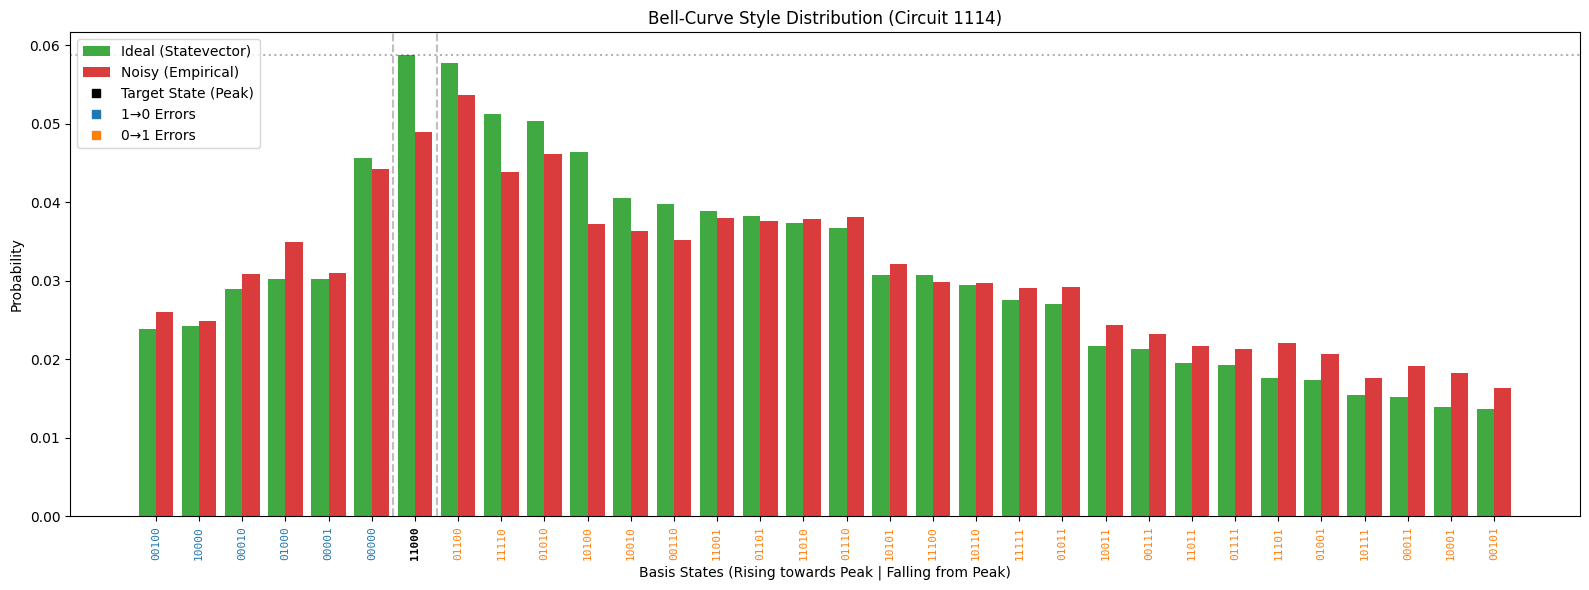

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def plot_bell_curve_distribution(ideal_probs, noisy_bits, circuit_id="0000"):
    # 1. Знаходимо найімовірніший ідеальний стан (наша ціль)
    target_state_idx = np.argmax(ideal_probs)
    target_bits = np.array([(target_state_idx >> (4 - i)) & 1 for i in range(5)])
    
    # 2. Рахуємо емпіричні ймовірності для шумних шотів
    noisy_indices = np.packbits(noisy_bits, axis=1, bitorder='little').flatten()
    noisy_counts = np.bincount(noisy_indices, minlength=32) / len(noisy_indices)
    
    # 3. Розподіляємо стани по групах
    left_side = []   # Помилки 1 -> 0
    center = []      # Ідеальний стан
    right_side = []  # Помилки 0 -> 1
    
    for idx in range(32):
        state_bits = np.array([(idx >> (4 - i)) & 1 for i in range(5)])
        
        zeros_to_ones = np.sum((target_bits == 0) & (state_bits == 1))
        ones_to_zeros = np.sum((target_bits == 1) & (state_bits == 0))
        
        item = {
            'idx': idx,
            'binary': f"{idx:05b}",
            'ideal': ideal_probs[idx],
            'noisy': noisy_counts[idx],
            'flips_total': zeros_to_ones + ones_to_zeros,
        }
        
        if idx == target_state_idx:
            center.append(item)
        elif ones_to_zeros > zeros_to_ones:
            left_side.append(item)
        else:
            right_side.append(item)
            
    # 4. СОРТУВАННЯ ДЛЯ СТВОРЕННЯ "ДЗВОНУ"
    # Права сторона: від найбільшої ймовірності до найменшої (спадання від центру)
    right_side.sort(key=lambda x: (-x['ideal'], x['flips_total']))
    
    # Ліва сторона: від найменшої ймовірності до найбільшої (зростання до центру)
    left_side.sort(key=lambda x: (x['ideal'], x['flips_total']))
    
    # Збираємо все разом: Ліво (зростання) -> Центр (пік) -> Право (спадання)
    sorted_data = left_side + center + right_side
    
    # 5. Підготовка до малювання
    x_positions = np.arange(len(sorted_data))
    ideal_vals = [d['ideal'] for d in sorted_data]
    noisy_vals = [d['noisy'] for d in sorted_data]
    x_labels = [d['binary'] for d in sorted_data]
    
    # Кольори для підписів
    x_colors = []
    for d in sorted_data:
        if d['idx'] == target_state_idx:
            x_colors.append('black')
        elif d in left_side:
            x_colors.append('#1f77b4') # Синій
        else:
            x_colors.append('#ff7f0e') # Оранжевий

    plt.figure(figsize=(16, 6))
    width = 0.4
    
    plt.bar(x_positions - width/2, ideal_vals, width, label='Ideal', alpha=0.9, color='#2ca02c')
    plt.bar(x_positions + width/2, noisy_vals, width, label='Noisy', alpha=0.9, color='#d62728')
    
    # Вертикальні лінії для відділення центру
    center_pos = len(left_side)
    plt.axvline(x=center_pos - 0.5, color='gray', linestyle='--', alpha=0.5)
    plt.axvline(x=center_pos + 0.5, color='gray', linestyle='--', alpha=0.5)
    
    # Додаємо горизонтальну лінію на рівні найвищого піку для візуального орієнтиру
    plt.axhline(y=max(ideal_vals), color='black', linestyle=':', alpha=0.3)

    plt.xticks(x_positions, x_labels, rotation=90, fontsize=8, family='monospace')
    
    for tick_label, color in zip(plt.gca().get_xticklabels(), x_colors):
        tick_label.set_color(color)
        if color == 'black':
            tick_label.set_fontweight('bold')

    plt.xlabel("Basis States (Rising towards Peak | Falling from Peak)")
    plt.ylabel("Probability")
    plt.title(f"Bell-Curve Style Distribution (Circuit {circuit_id})")
    
    legend_elements = [
        Patch(facecolor='#2ca02c', alpha=0.9, label='Ideal (Statevector)'),
        Patch(facecolor='#d62728', alpha=0.9, label='Noisy (Empirical)'),
        plt.Line2D([0], [0], color='black', marker='s', linestyle='None', label='Target State (Peak)'),
        plt.Line2D([0], [0], color='#1f77b4', marker='s', linestyle='None', label='1→0 Errors'),
        plt.Line2D([0], [0], color='#ff7f0e', marker='s', linestyle='None', label='0→1 Errors')
    ]
    plt.legend(handles=legend_elements, loc='upper left')
    
    plt.tight_layout()
    plt.show()

# Викликаємо функцію
plot_bell_curve_distribution(ideal_probs, noisy_bits, circuit_id="1114")

In [26]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

train_clean_path = "../data/1_clean_train.h5"
train_noisy_path = "../data/3_noisy_train.h5"

def unpack_bitstrings(packed_array, num_bits=5):
    return np.unpackbits(packed_array, axis=1)[:, :num_bits]

mismatched_circuits = []
match_count = 0

with h5py.File(train_clean_path, 'r') as f_c, \
     h5py.File(train_noisy_path, 'r') as f_n:
    
    print("Аналізуємо всі 2000 схем...")
    
    for i in range(2000):
        key = f"circuit_{i:04d}"
        
        # 1. Ідеальний пік
        ideal_probs = f_c[f'probs/{key}'][:]
        ideal_peak_idx = np.argmax(ideal_probs)
        
        # 2. Шумний пік
        packed = f_n[f'noisy_bitstrings/{key}'][:]
        noisy_bits = unpack_bitstrings(packed)
        
        # Перетворюємо шоти в індекси і рахуємо частоти
        noisy_indices = np.packbits(noisy_bits, axis=1, bitorder='little').flatten()
        noisy_counts = np.bincount(noisy_indices, minlength=32)
        noisy_peak_idx = np.argmax(noisy_counts)
        
        # 3. Порівнюємо
        if ideal_peak_idx == noisy_peak_idx:
            match_count += 1
        else:
            # Зберігаємо інформацію про розбіжність
            mismatched_circuits.append({
                'circuit': key,
                'ideal_peak': f"{ideal_peak_idx:05b}",
                'ideal_prob': ideal_probs[ideal_peak_idx],
                'noisy_peak': f"{noisy_peak_idx:05b}",
                'noisy_prob': noisy_counts[noisy_peak_idx] / 10000
            })

# Виводимо результати
print(f"\nВсього схем: 2000")
print(f"Збіг піків:  {match_count} ({match_count/20:.1f}%)")
print(f"Розбіжність: {len(mismatched_circuits)} ({len(mismatched_circuits)/20:.1f}%)")

# Показуємо перші 10 випадків розбіжності
if len(mismatched_circuits) > 0:
    print("\n=== Приклади схем, де шум змінив найімовірніший стан ===")
    for item in mismatched_circuits[:10]:
        print(f"Схема {item['circuit']}: Ідеал={item['ideal_peak']} (p={item['ideal_prob']:.3f}) "
              f"-> Шум={item['noisy_peak']} (p={item['noisy_prob']:.3f})")
else:
    print("\nДивовижно! Шум жодного разу не змінив найімовірніший стан.")

Аналізуємо всі 2000 схем...

Всього схем: 2000
Збіг піків:  1877 (93.8%)
Розбіжність: 123 (6.2%)

=== Приклади схем, де шум змінив найімовірніший стан ===
Схема circuit_0009: Ідеал=11000 (p=0.059) -> Шум=01100 (p=0.054)
Схема circuit_0038: Ідеал=11101 (p=0.120) -> Шум=00101 (p=0.095)
Схема circuit_0046: Ідеал=00011 (p=0.234) -> Шум=10011 (p=0.179)
Схема circuit_0051: Ідеал=00001 (p=0.252) -> Шум=11010 (p=0.178)
Схема circuit_0070: Ідеал=01111 (p=0.087) -> Шум=01000 (p=0.068)
Схема circuit_0074: Ідеал=01010 (p=0.128) -> Шум=01001 (p=0.096)
Схема circuit_0076: Ідеал=01100 (p=0.174) -> Шум=10000 (p=0.140)
Схема circuit_0088: Ідеал=10000 (p=0.164) -> Шум=00010 (p=0.128)
Схема circuit_0096: Ідеал=10010 (p=0.155) -> Шум=00000 (p=0.123)
Схема circuit_0113: Ідеал=01011 (p=0.162) -> Шум=00001 (p=0.123)


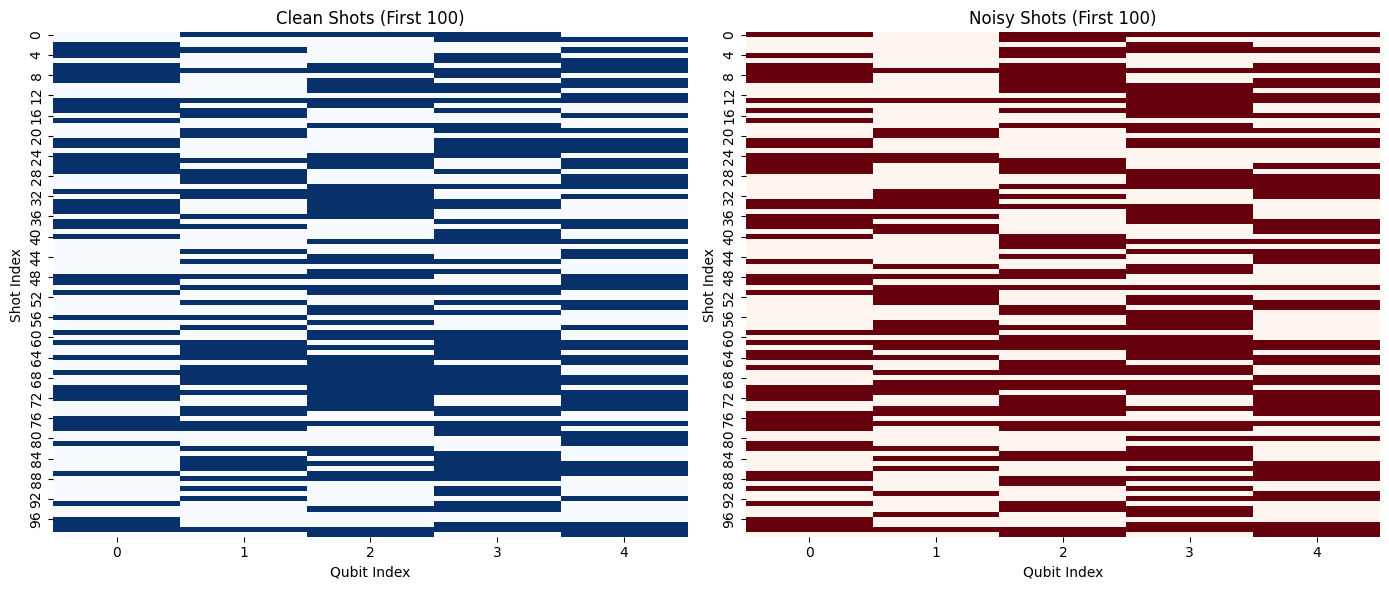

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(clean_bits[:100], cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Clean Shots (First 100)")
axes[0].set_xlabel("Qubit Index")
axes[0].set_ylabel("Shot Index")

sns.heatmap(noisy_bits[:100], cmap="Reds", cbar=False, ax=axes[1])
axes[1].set_title("Noisy Shots (First 100)")
axes[1].set_xlabel("Qubit Index")
axes[1].set_ylabel("Shot Index")

plt.tight_layout()
plt.show()

In [30]:
import time

tvd_scores = []
total_clean_ones = np.zeros(5)
total_noisy_ones = np.zeros(5)
total_shots = 0
num_circuits = 2000

print("Processing all 2000 circuits... This might take a minute.")

start_time = time.time()

with h5py.File(train_clean_path, 'r') as f_c, h5py.File(train_noisy_path, 'r') as f_n:
    for i in range(num_circuits):
        key = f"circuit_{i:04d}"
        
        ideal_probs = f_c[f'probs/{key}'][:]
        clean_bits = unpack_bitstrings(f_c[f'clean_bitstrings/{key}'][:])
        noisy_bits = unpack_bitstrings(f_n[f'noisy_bitstrings/{key}'][:])
        
        total_clean_ones += clean_bits.sum(axis=0)
        total_noisy_ones += noisy_bits.sum(axis=0)
        total_shots += len(clean_bits)
        
        noisy_indices = np.packbits(noisy_bits, axis=1, bitorder='little').flatten()
        noisy_probs = np.bincount(noisy_indices, minlength=32) / len(noisy_indices)
        
        tvd = 0.5 * np.sum(np.abs(ideal_probs - noisy_probs))
        tvd_scores.append(tvd)

tvd_scores = np.array(tvd_scores)
end_time = time.time()

print(f"Done in {end_time - start_time:.2f} seconds.")
print(f"Mean TVD: {tvd_scores.mean():.4f}")
print(f"Worst TVD: {tvd_scores.max():.4f}")
print(f"Best TVD:  {tvd_scores.min():.4f}")

Processing all 2000 circuits... This might take a minute.
Done in 2.66 seconds.
Mean TVD: 0.1628
Worst TVD: 0.2735
Best TVD:  0.0416


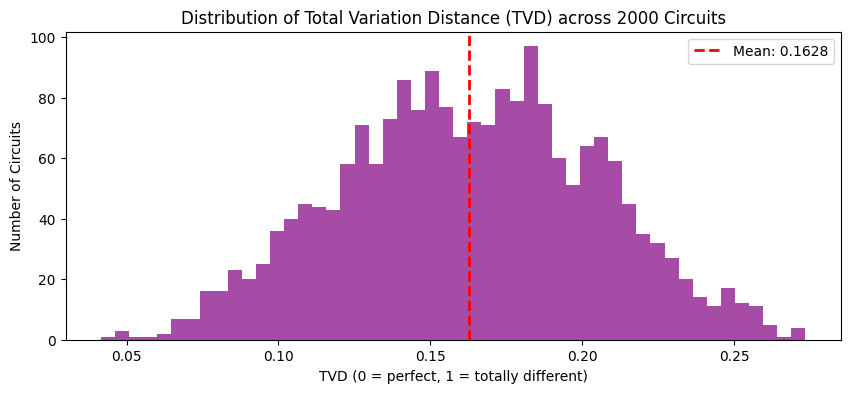

In [32]:
plt.figure(figsize=(10, 4))
plt.hist(tvd_scores, bins=50, color='purple', alpha=0.7)
plt.axvline(tvd_scores.mean(), color='red', linestyle='dashed', linewidth=2, label=f'Mean: {tvd_scores.mean():.4f}')
plt.title("Distribution of Total Variation Distance (TVD) across 2000 Circuits")
plt.xlabel("TVD (0 = perfect, 1 = totally different)")
plt.ylabel("Number of Circuits")
plt.legend()
plt.show()

# Feature enginearing

**Goal.** TODO

**Input.** TODO

**Conclusion.** TODO, after running the notebook.
